In [1]:
%matplotlib ipympl

In [2]:
import mlflow
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import linregress

from benchmark.config import EXPERIMENT_NAME


In [3]:
exp = mlflow.set_experiment(EXPERIMENT_NAME)

In [4]:
# one row per child run (a model x system-prompt pair) with each scorer's
# mean over the run; the model is only recorded in the run name. The
# per-trace "<scorer>/by_price_time" series only show their last point in a
# runs table, so they are left out.
run_name = "sweep-20261030-1041"
# the parentRunId tag holds the parent's run_id, not its name, so look the
# parent up by name first
parent = mlflow.search_runs(
    experiment_ids=[exp.experiment_id],
    filter_string=f"tags.mlflow.runName = '{run_name}'",
)
# assert len(parent) == 1, f"expected one run named {run_name!r}, found {len(parent)}"
runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{parent.run_id.iloc[0]}'",
)

In [14]:
runs["run_id"]

0    627872674c2645ad80f0cbf6dd7570e2
1    3ed577ee4d5e4c7790754e2eee5d0641
Name: run_id, dtype: object

In [5]:
# every trace (one per predict call) of every child run, tagged with the run
# it came from. The record's inputs sit under request["inputs"], the market
# category is a tag copied onto the trace, and each scorer's value is an
# assessment on the trace.
traces = pd.concat(
    [
        mlflow.search_traces(locations=[exp.experiment_id], run_id=run_id).assign(
            run=name
        )
        for run_id, name in zip(runs["run_id"], runs["tags.mlflow.runName"])
    ],
    ignore_index=True,
)

In [ ]:
def assessment_value(assessments: list, name: str) -> float | None:
    # scorer outputs are stored as "feedback", dataset expectations (the
    # market's own probability) as "expectation"
    for a in assessments:
        if a["assessment_name"] == name:
            return (a.get("feedback") or a["expectation"])["value"]
    return None


In [37]:
traces

,trace_id,trace,client_request_id,state,request_time,execution_duration,request,response,trace_metadata,tags,spans,assessments,run
0,tr-146b645a5a23cdb3439f2c93240a56b6,"{""info"": {""trace_id"": ""tr-146b645a5a23cdb3439f...",None,OK,1793372260626,7965,"{'model': 'claude-sonnet-5-5', 'system_prompt'...","{'probability': 0.8, 'raw': 'Cabinet-level dep...",{'mlflow.modelId': 'm-8a412bb25d364995a15d0e41...,{'mlflow.artifactLocation': 'file:C:/Users/and...,"[{'trace_id': 'FGtkWlojzbNDnyyTJApWtg==', 'spa...",[{'assessment_id': 'a-3764b465a5be426b98f6ad66...,claude-sonnet-5-5-no-cutoff
1,tr-f5ae826ded2bb282d3d8eed54936a552,"{""info"": {""trace_id"": ""tr-f5ae826ded2bb282d3d8...",None,OK,1793372260167,12828,"{'model': 'claude-sonnet-5-5', 'system_prompt'...","{'probability': 0.93, 'raw': 'Context: Israel ...",{'mlflow.modelId': 'm-8a412bb25d364995a15d0e41...,{'mlflow.artifactLocation': 'file:C:/Users/and...,"[{'trace_id': '9a6Cbe0rsoLT2O7VSTalUg==', 'spa...",[{'assessment_id': 'a-cf6c1c4e551a4cdb9ab26f6e...,claude-sonnet-5-5-no-cutoff
2,tr-bd6d18193b14c4dd9b17283386e038b5,"{""info"": {""trace_id"": ""tr-bd6d18193b14c4dd9b17...",None,OK,1793372260022,7897,"{'model': 'claude-sonnet-5-5', 'system_prompt'...","{'probability': 0.002, 'raw': 'Abolishing the ...",{'mlflow.modelId': 'm-8a412bb25d364995a15d0e41...,{'mlflow.artifactLocation': 'file:C:/Users/and...,"[{'trace_id': 'vW0YGTsUxN2bFygzhuA4tQ==', 'spa...",[{'assessment_id': 'a-1ee04135895a44fb9d02bb90...,claude-sonnet-5-5-no-cutoff
3,tr-3a9718e5c643322cff638f8a1ba316fa,"{""info"": {""trace_id"": ""tr-3a9718e5c643322cff63...",None,OK,1793372259863,9514,"{'model': 'claude-sonnet-5-5', 'system_prompt'...","{'probability': 0.2, 'raw': 'I couldn't check ...",{'mlflow.modelId': 'm-8a412bb25d364995a15d0e41...,{'mlflow.artifactLocation': 'file:C:/Users/and...,"[{'trace_id': 'OpcY5cZDMiz/Y4+KG6MW+g==', 'spa...",[{'assessment_id': 'a-e4278dd9f3004abda3acb0cd...,claude-sonnet-5-5-no-cutoff
4,tr-8b6788284c4a511da83631cfc153c700,"{""info"": {""trace_id"": ""tr-8b6788284c4a511da836...",None,OK,1793372259571,7989,"{'model': 'claude-sonnet-5-5', 'system_prompt'...","{'probability': 0.02, 'raw': 'Andrew Mountbatt...",{'mlflow.modelId': 'm-8a412bb25d364995a15d0e41...,{'mlflow.artifactLocation': 'file:C:/Users/and...,"[{'trace_id': 'i2eIKExKUR2oNjHPwVPHAA==', 'spa...",[{'assessment_id': 'a-129d5f515688498fbec766c5...,claude-sonnet-5-5-no-cutoff
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1964,tr-f890319d4cb4018c73fd50c053785aa7,"{""info"": {""trace_id"": ""tr-f890319d4cb4018c73fd...",None,OK,1793371317605,9837,"{'model': 'claude-sonnet-5-5', 'system_prompt'...","{'probability': 0.33, 'raw': 'I'm working from...",{'mlflow.modelId': 'm-8a412bb25d364995a15d0e41...,{'mlflow.artifactLocation': 'file:C:/Users/and...,"[{'trace_id': '+JAxnUy0AYxz/VDAU3hapw==', 'spa...",[{'assessment_id': 'a-a43aaa1e62694458a2167f6e...,claude-sonnet-5-5-cutoff
1965,tr-2a0ee888d9130fe515cc9ec69020c2dc,"{""info"": {""trace_id"": ""tr-2a0ee888d9130fe515cc...",None,OK,1793371317604,10317,"{'model': 'claude-sonnet-5-5', 'system_prompt'...","{'probability': 0.03, 'raw': 'The US had no pl...",{'mlflow.modelId': 'm-8a412bb25d364995a15d0e41...,{'mlflow.artifactLocation': 'file:C:/Users/and...,"[{'trace_id': 'Kg7oiNkTD+UVzJ7GkCDC3A==', 'spa...",[{'assessment_id': 'a-306efc10ceee49a293a6d0fb...,claude-sonnet-5-5-cutoff
1966,tr-fc3a05d4fa3c83ec06ab495bf6b77de2,"{""info"": {""trace_id"": ""tr-fc3a05d4fa3c83ec06ab...",None,OK,1793371317604,11782,"{'model': 'claude-sonnet-5-5', 'system_prompt'...","{'probability': 0.07, 'raw': 'FL-18 is a safel...",{'mlflow.modelId': 'm-8a412bb25d364995a15d0e41...,{'mlflow.artifactLocation': 'file:C:/Users/and...,"[{'trace_id': '/DoF1Po8g+wGq0lb9rd94g==', 'spa...",[{'assessment_id': 'a-9b5d7c9f92454117b661325b...,claude-sonnet-5-5-cutoff
1967,tr-c0e4b077dfdb216a1a8600ae5e4f7f77,"{""info"": {""trace_id"": ""tr-c0e4b077dfdb216a1a86...",None,OK,1793371317603,14132,"{'model': 'claude-sonnet-5-5', 'sys

In [39]:
trace_df = pd.DataFrame(
    {
        "run": traces["run"],
        "model": traces["request"].map(lambda r: r["model"]),
        "system_prompt": traces["request"].map(lambda r: r["system_prompt"]),
        # a tag on the child run rather than on the trace, as "YYYY-MM"; taken
        # as the last day of that month so it compares against as_of
        "training_data_cutoff": pd.PeriodIndex(
            traces["run"].map(
                dict(
                    zip(runs["tags.mlflow.runName"], runs["tags.training_data_cutoff"])
                )
            ),
            freq="M",
        )
        .to_timestamp(how="end")
        .normalize(),
        "category": traces["tags"].map(lambda t: t.get("event_category")),
        "market_title": traces["request"].map(lambda r: r["inputs"]["market_title"]),
        "response": traces["response"].map(lambda r: r and r["raw"]),
        "as_of": traces["request"].map(lambda r: pd.Timestamp(r["inputs"]["as_of"])),
        "predicted_probability": traces["response"].map(
            lambda r: r and r["probability"]
        ),
        "market_probability": traces["assessments"].map(
            lambda a: assessment_value(a, "market_probability")
        ),
        "state": traces["state"],
    }
)
trace_df = trace_df[trace_df["system_prompt"] == "no-cutoff"]
trace_df = trace_df[trace_df["as_of"] > pd.Timestamp("2026-06-30")]

In [40]:
trace_df

,run,model,system_prompt,training_data_cutoff,category,market_title,response,as_of,predicted_probability,market_probability,state
3,claude-sonnet-5-5-no-cutoff,claude-sonnet-5-5,no-cutoff,2026-06-30,finance,Will NVIDIA (NVDA) hit (HIGH) $232 in October?,"I couldn't check NVDA's current price, so this...",2026-09-26 00:00:16,0.20,0.50,OK
6,claude-sonnet-5-5-no-cutoff,claude-sonnet-5-5,no-cutoff,2026-06-30,finance,Natural Gas (NG) Up or Down on September 21?,"September 21, 2026 is a Monday. The close is c...",2026-09-19 00:00:28,0.49,0.74,OK
10,claude-sonnet-5-5-no-cutoff,claude-sonnet-5-5,no-cutoff,2026-06-30,elections,Will the margin of victory for Republicans in ...,Ohio's 7th district (Max Miller) was redrawn i...,2026-07-12 04:00:00,0.50,0.20,OK
11,claude-sonnet-5-5-no-cutoff,claude-sonnet-5-5,no-cutoff,2026-06-30,elections,Will James Fishback drop out of the Florida Go...,James Fishback is a long-shot candidate in the...,2026-07-10 04:00:00,0.04,0.27,OK
20,claude-sonnet-5-5-no-cutoff,claude-sonnet-5-5,no-cutoff,2026-06-30,elections,Will Ed Case be the Democratic nominee for HI-01?,"Ed Case is the incumbent in HI-01, and Hawaii'...",2026-07-12 04:00:00,0.77,0.51,OK
...,...,...,...,...,...,...,...,...,...,...,...
955,claude-sonnet-5-5-no-cutoff,claude-sonnet-5-5,no-cutoff,2026-06-30,finance,Will Blackstone (BX) Q2 total assets under man...,I didn't look up Blackstone's reported figures...,2026-07-08 00:00:05,0.37,0.50,OK
964,claude-sonnet-5-5-no-cutoff,claude-sonnet-5-5,no-cutoff,2026-06-30,economics,Will average **gas prices** be above $3.9400?,"I can't see the current Kansas AAA price, and ...",2026-10-26 04:00:00,0.45,0.18,OK
966,claude-sonnet-5-5-no-cutoff,claude-sonnet-5-5,no-cutoff,2026-06-30,finance,Robinhood (HOOD) Up or Down on October 6?,Daily up/down for a volatile stock with no spe...,2026-10-06 00:00:24,0.52,0.50,OK
967,claude-sonnet-5-5-no-cutoff,claude-sonnet-5-5,no-cutoff,2026-06-30,finance,EWY (EWY) Up or Down on September 17?,Daily up/down for an ETF with no other informa...,2026-09-17 00:00:16,0.52,0.72,OK


In [41]:
trace_df["error"] = abs(
    trace_df["market_probability"] - trace_df["predicted_probability"]
)

In [42]:
trace_df[
    [
        "market_title",
        "response",
        "as_of",
        "error",
        "predicted_probability",
        "market_probability",
    ]
]

,market_title,response,as_of,error,predicted_probability,market_probability
3,Will NVIDIA (NVDA) hit (HIGH) $232 in October?,"I couldn't check NVDA's current price, so this...",2026-09-26 00:00:16,0.30,0.20,0.50
6,Natural Gas (NG) Up or Down on September 21?,"September 21, 2026 is a Monday. The close is c...",2026-09-19 00:00:28,0.25,0.49,0.74
10,Will the margin of victory for Republicans in ...,Ohio's 7th district (Max Miller) was redrawn i...,2026-07-12 04:00:00,0.30,0.50,0.20
11,Will James Fishback drop out of the Florida Go...,James Fishback is a long-shot candidate in the...,2026-07-10 04:00:00,0.23,0.04,0.27
20,Will Ed Case be the Democratic nominee for HI-01?,"Ed Case is the incumbent in HI-01, and Hawaii'...",2026-07-12 04:00:00,0.26,0.77,0.51
...,...,...,...,...,...,...
955,Will Blackstone (BX) Q2 total assets under man...,I didn't look up Blackstone's reported figures...,2026-07-08 00:00:05,0.13,0.37,0.50
964,Will average **gas prices** be above $3.9400?,"I can't see the current Kansas AAA price, and ...",2026-10-26 04:00:00,0.27,0.45,0.18
966,Robinhood (HOOD) Up or Down on October 6?,Daily up/down for a volatile stock with no spe...,2026-10-06 00:00:24,0.02,0.52,0.50
967,EWY (EWY) Up or Down on September 17?,Daily up/down for an ETF with no other informa...,2026-09-17 00:00:16,0.20,0.52,0.72


In [22]:
# months from the model's training cutoff to the market price time, positive
# when the market was priced after the cutoff (fractional: days / mean month)
trace_df["time_diff"] = (
    trace_df["as_of"] - trace_df["training_data_cutoff"]
).dt.days / (365.25 / 12)


Text(0.5, 0, 'months after training cutoff')

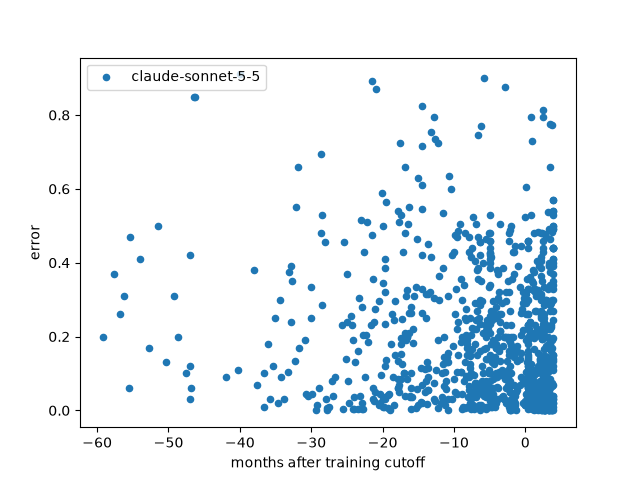

In [23]:
# one series per model so the legend says which model each point is
ax = None
for i, (model, points) in enumerate(trace_df.groupby("model")):
    ax = points.plot.scatter(
        x="time_diff", y="error", label=model, color=f"C{i}", ax=ax
    )
ax.set_xlabel("months after training cutoff")

In [24]:
# rows whose forecast could not be parsed have no error and would make the
# fit NaN
scored = trace_df.dropna(subset=["error"])


In [25]:
fit = smf.ols("error ~ time_diff + C(model)", data=scored).fit()


In [26]:
fit.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  error   R-squared:                       0.013
Model:                            OLS   Adj. R-squared:                  0.012
Method:                 Least Squares   F-statistic:                     12.77
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           0.000369
Time:                        16:34:25   Log-Likelihood:                 284.63
No. Observations:                 966   AIC:                            -565.3
Df Residuals:                     964   BIC:                            -555.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1803      0.007     26.877      0.000       0.167       0.193
time_diff     -0.0018      0.001     -3.574      0.000      -0.003      -0.001
==============================================================================
Omnibus:                      186.927   Durbin-Watson:                   1.798
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              313.886
Skew:                           1.229   Prob(JB):                     6.93e-69
Kurtosis:                       4.325   Cond. No.                         15.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [27]:
# the same fit per model, slope in error per month with its p-value
by_model = scored.groupby("model").apply(
    lambda g: pd.Series(linregress(g["time_diff"], g["error"])._asdict()),
    include_groups=False,
)


In [28]:
by_model[["slope", "intercept", "rvalue", "pvalue"]]


,slope,intercept,rvalue,pvalue
model,,,,
claude-sonnet-5-5,-0.001819,0.18028,-0.114359,0.000369


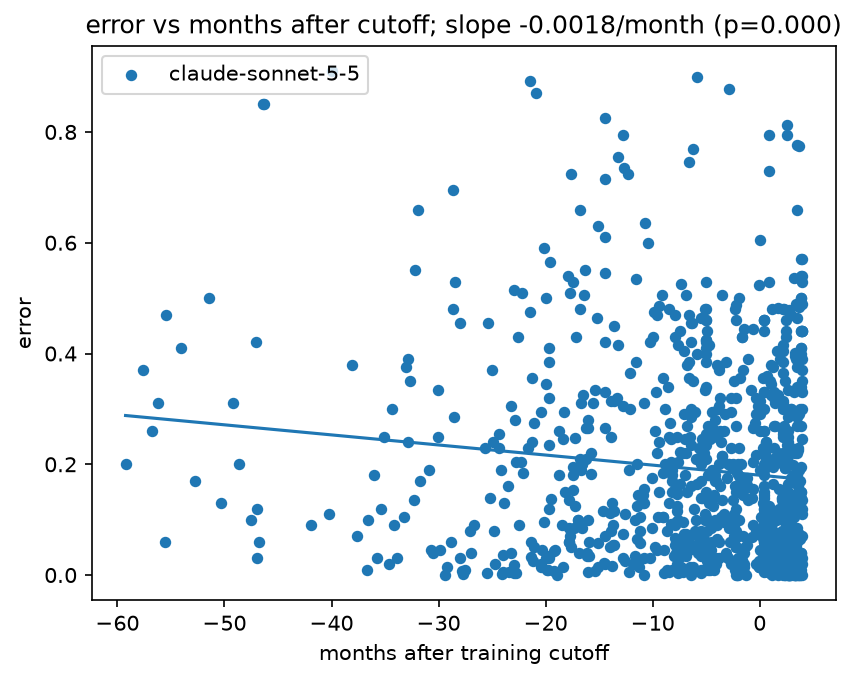

In [29]:
# the fitted line per model: common slope, model-specific intercept
for i, (model, points) in enumerate(scored.groupby("model")):
    x = points["time_diff"].sort_values()
    ax.plot(
        x,
        fit.predict(pd.DataFrame({"time_diff": x, "model": model})),
        color=f"C{i}",
    )
ax.set_title(
    f"error vs months after cutoff; slope {fit.params['time_diff']:.4f}/month (p={fit.pvalues['time_diff']:.3f})"
)
ax.figure
